# Linear models

In [57]:
import scanpy as sc 
import pandas as pd
from sklearn.metrics import classification_report 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

adata = sc.read_h5ad("data/annotated_pbmc.h5ad")

### First model: Logistic Regression using broad labels ("B cell, T cell") and 1987 genes

In [58]:
X = adata.X
y = adata.obs["cell_type"]
X.shape

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=.2,
    random_state=42,
    stratify=y # assigns labels with the same proportion as the train  y
)

# create the model
model = LogisticRegression(
    max_iter=1000
)
# fit the model to X train and y train, it's learning now
model.fit(X_train, y_train)

# make prediction using X test
y_pred = model.predict(X_test)

# evaluate
accuracy = accuracy_score(y_test, y_pred)
print(f"Model 1 Accuracy: {accuracy:.3f}")

print(adata.shape)
print(X.shape)
print(y.value_counts())
print(X_train.shape)
print(X_test.shape)
print(model.classes_)
print(accuracy_score(y_test, y_pred))

Model 1 Accuracy: 0.964
(2616, 1987)
(2616, 1987)
cell_type
T cell                     1075
Classical monocyte          509
B cell                      338
Memory/effector T cell      247
NK cell                     158
FCGR3A+ monocyte            141
NK/cytotoxic lymphocyte     117
Dendritic/APC                23
Megakaryocyte                 8
Name: count, dtype: int64
(2092, 1987)
(524, 1987)
['B cell' 'Classical monocyte' 'Dendritic/APC' 'FCGR3A+ monocyte'
 'Megakaryocyte' 'Memory/effector T cell' 'NK cell'
 'NK/cytotoxic lymphocyte' 'T cell']
0.9637404580152672


In [59]:
print(classification_report(y_test, y_pred))

                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.96      0.99      0.98       102
          Dendritic/APC       1.00      0.40      0.57         5
       FCGR3A+ monocyte       0.96      0.96      0.96        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.91      0.86      0.88        49
                NK cell       0.94      0.97      0.95        32
NK/cytotoxic lymphocyte       0.95      0.78      0.86        23
                 T cell       0.97      1.00      0.98       215

               accuracy                           0.96       524
              macro avg       0.97      0.88      0.91       524
           weighted avg       0.96      0.96      0.96       524



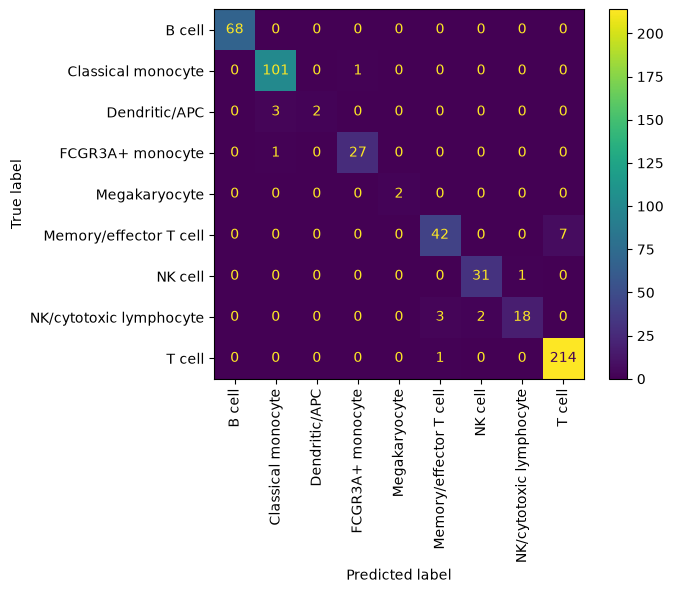

In [60]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=90)
plt.show()
# diagonal is the number of cells the model got correct
# off-diagonal shows what was misclassified

The model is confusing T/CD4 T cells with Naive T cells. This first model using 1987 gene features and 2092 cells is giving us 96% accuracy. Would using the first 10 pca features improve the model? Or if I did that with random forest or a pytorch neural network rather than logistic regression? 

### Second model: Logistic Regression using 50 pcs as features
Doing truncated SVD after splitting train and test to avoid data leakage. After splitting into the 4 subsets, I'll use truncatedSVD to find the 50 pcs on X_train, then apply those learned coordinates to X_test using transform, not fit transform, to prevent data leakage. y_train is untouched. Then, I'll run log reg to predict y_test.

In [61]:
# start with original X and y
X = adata.X
y = adata.obs["cell_type"]

# split data before doing pca
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# truncatedSVD is for sparse matrices that gives us pca-like dim reduction
svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

# svd is a model/object that can store the 50pcs and estimate
# train svd with train data then translate into new coordinate system 
X_train_pca = svd.fit_transform(X_train)
X_test_pca = svd.transform(X_test)
# you end up with X test and train in new coordinate system

# 50 pcs model 
model_50 = LogisticRegression(max_iter=5000)
model_50.fit(X_train_pca, y_train)
y_pred_50 = model_50.predict(X_test_pca)
accuracy_50 = accuracy_score(y_test, y_pred_50)
print(f"50-component accuracy: {accuracy_50:.3f}")
print(classification_report(y_test, y_pred_50))

50-component accuracy: 0.979
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.98      1.00      0.99       102
          Dendritic/APC       1.00      0.80      0.89         5
       FCGR3A+ monocyte       1.00      0.96      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.94      0.92      0.93        49
                NK cell       0.97      0.97      0.97        32
NK/cytotoxic lymphocyte       0.95      0.83      0.88        23
                 T cell       0.98      1.00      0.99       215

               accuracy                           0.98       524
              macro avg       0.98      0.94      0.96       524
           weighted avg       0.98      0.98      0.98       524



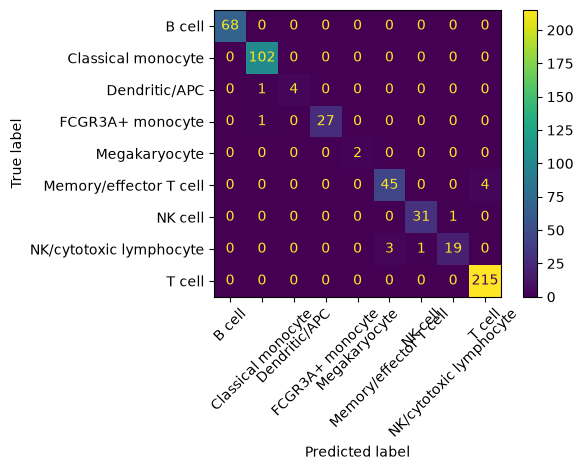

In [62]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_50,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

### Third model: logistic regression using first 10 pca components as features 

10-component accuracy: 0.992
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.99      1.00      1.00       102
          Dendritic/APC       1.00      1.00      1.00         5
       FCGR3A+ monocyte       1.00      0.96      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       1.00      0.98      0.99        49
                NK cell       0.94      1.00      0.97        32
NK/cytotoxic lymphocyte       1.00      0.91      0.95        23
                 T cell       1.00      1.00      1.00       215

               accuracy                           0.99       524
              macro avg       0.99      0.98      0.99       524
           weighted avg       0.99      0.99      0.99       524



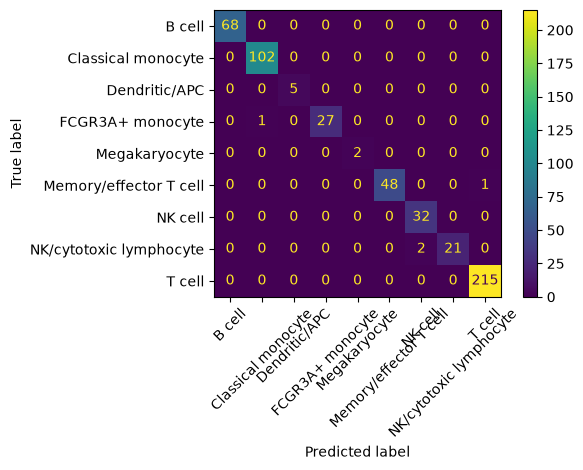

In [63]:
# just take first 10 pcs
X_train_10 = X_train_pca[:, :10]
X_test_10 = X_test_pca[:, :10]

# 10 pcs model 
model_10 = LogisticRegression(max_iter=5000)
model_10.fit(X_train_10, y_train)
y_pred_10 = model_10.predict(X_test_10)
accuracy_10 = accuracy_score(y_test, y_pred_10)
print(f"10-component accuracy: {accuracy_10:.3f}")
print(classification_report(y_test, y_pred_10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_10,
    xticks_rotation=45
)

plt.tight_layout()
plt.show()

The accuracy between 50 pcs and 10 pcs increased by 1.3 points, the later pcs may have been adding noise. The first 10 captures the most necessary variations. 

Saving the results of each model

In [64]:
model_results = {
    "Logistic regression, 1987 genes": 0.96,
    "Logistic regression, 50 SVD components": 0.97,
    "Logistic regression, 10 SVD components": 0.99
}


### Fourth model: Random Forest using first 10 prinicple components

In [65]:
# set up the model
rf_model = RandomForestClassifier(
    n_estimators=100, # 100 trees
    random_state=42
)

# train it 
rf_model.fit(
    X_train_10, y_train
)

# evaluate
y_pred_rf = rf_model.predict(X_test_10)

# calculate accuracy
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(f"Random Forest accuracy: {rf_accuracy:.3f}")
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Random Forest accuracy: 0.987
                         precision    recall  f1-score   support

                 B cell       1.00      1.00      1.00        68
     Classical monocyte       0.99      0.99      0.99       102
          Dendritic/APC       1.00      0.80      0.89         5
       FCGR3A+ monocyte       0.97      1.00      0.98        28
          Megakaryocyte       1.00      1.00      1.00         2
 Memory/effector T cell       0.98      0.94      0.96        49
                NK cell       0.97      1.00      0.98        32
NK/cytotoxic lymphocyte       1.00      0.91      0.95        23
                 T cell       0.99      1.00      0.99       215

               accuracy                           0.99       524
              macro avg       0.99      0.96      0.97       524
           weighted avg       0.99      0.99      0.99       524



In [66]:
model_results["Random forest"] = 0.987
print(model_results)

{'Logistic regression, 1987 genes': 0.96, 'Logistic regression, 50 SVD components': 0.97, 'Logistic regression, 10 SVD components': 0.99, 'Random forest': 0.987}


A more complicated model didn't improve accuracy, this dataset is linearly separable. RF, which is non linear, didn't achieve much, and lowered the accuracy.

## Model comparison
I use feature importance to see which pcs were most useful.


In [67]:
# random forest has a concept, feature importances that tell you which pcs were most useful 
feature_importance = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(10)],
    "importance": rf_model.feature_importances_
})

feature_importance.sort_values(
    "importance",
    ascending=False
)

,PC,importance
2,PC3,0.240076
1,PC2,0.208077
3,PC4,0.206284
5,PC6,0.104634
4,PC5,0.100988
0,PC1,0.073819
7,PC8,0.031009
9,PC10,0.013056
8,PC9,0.011268
6,PC7,0.010788


PCs 2-4 contributed the most, almost 65% of the whole feature importance. Follow up question is, what genes make up these pcs? what genes are the most biologically indicative?

In [68]:
svd.components_.shape

(50, 1987)

In [69]:
svd.components_[2]

array([ 0.02429345,  0.00013071, -0.00124706, ..., -0.00090125,
        0.01455521,  0.02909435], shape=(1987,), dtype=float32)

Making a df just for pc 3 to see which genes affect pc 3 most 

In [70]:
pc3_loadings = pd.DataFrame({
    "gene": adata.var_names,
    "loading": svd.components_[2]
})
pc3_loadings["abs_loading"] = pc3_loadings["loading"].abs()
pc3_loadings.sort_values("abs_loading", ascending=False).head(20)["gene"]

1877        NKG7
636          LTB
654     HLA-DPB1
1598        CCL5
1852       CD79A
646     HLA-DRB1
268         GNLY
653     HLA-DPA1
647     HLA-DQA1
1646       CD79B
546         GZMA
1715        CST7
1872        CD37
648     HLA-DQB1
1317        GZMB
1110        CTSW
1093       MS4A1
1010        PRF1
1007        SRGN
1368       TCL1A
Name: gene, dtype: object

SVD component 3 captures substantial variation in immune-cell expression programs, including cytotoxic lymphocyte, B-cell, and antigen-presentation signatures. Lets look at component 2 and 4:

In [71]:
def get_top_genes(component, n=20):
    loadings = pd.DataFrame({
        "gene": adata.var_names,
        "loading": svd.components_[component]
    })
    
    loadings["abs_loading"] = loadings["loading"].abs()
    
    return loadings.sort_values(
        "abs_loading",
        ascending=False
    ).head(n)

get_top_genes(1).head(20)["gene"]

1714       CST3
636         LTB
129      S100A8
1833     TYROBP
1459       IL32
1116    PTPRCAP
639        AIF1
637        LST1
965        FCN1
1939     LGALS1
158      FCER1G
1966       TYMP
1937     LGALS2
120        CTSS
1598       CCL5
813        SAT1
1877       NKG7
1535      COTL1
370        GPX1
1351       NPC2
Name: gene, dtype: object

Component 2 appears to capture variation associated with myeloid/monocyte identity.

In [72]:
get_top_genes(3).head(20)["gene"]

654     HLA-DPB1
1877        NKG7
653     HLA-DPA1
646     HLA-DRB1
537         IL7R
647     HLA-DQA1
1852       CD79A
1646       CD79B
1459        IL32
268         GNLY
636          LTB
648     HLA-DQB1
1317        GZMB
1715        CST7
1598        CCL5
546         GZMA
1093       MS4A1
1010        PRF1
466       FGFBP2
130       S100A6
Name: gene, dtype: object

So Component 4 appears to capture a broad lymphocyte/immune-state axis, distinguishing populations with different immune expression programs.

### 5-fold Cross validation of the logistic regression model to fine tune parameters


In [73]:
# we make a new df using the model's coefs and classes 
# it shows how much each cell type is associated with each pc 
coef_df = pd.DataFrame(
    model_10.coef_,
    index=model_10.classes_,
    columns=[f"Component {i+1}" for i in range(10)]
)

coef_df

,Component 1,Component 2,Component 3,Component 4,Component 5,Component 6,Component 7,Component 8,Component 9,Component 10
B cell,-0.066512,0.105010,-2.221669,0.459895,-0.444531,-0.687901,-0.144913,-0.034948,-0.273028,0.168641
Classical monocyte,0.531636,1.312364,-0.130482,-0.011108,0.821625,-0.466379,-0.229479,0.256935,-0.290094,0.176293
Dendritic/APC,0.592104,0.237541,-1.163107,0.415446,-0.192367,-0.778087,0.145107,-1.109428,-0.508534,0.213368
FCGR3A+ monocyte,-0.180284,0.990187,0.120921,-0.394673,-1.289761,0.377720,-0.348329,1.530338,-0.042323,0.108016
Megakaryocyte,0.023673,0.192498,0.065826,-0.043677,-0.194889,0.115104,0.567635,0.185407,0.182608,0.004060
Memory/effector T cell,-0.469001,-0.680659,0.713777,-0.583800,1.173727,1.704895,-0.300162,0.266998,0.413347,0.173298
NK cell,0.485518,-0.484560,2.019404,0.924139,-0.144236,-0.969261,0.459711,0.328320,0.703708,-0.007537
NK/cytotoxic lymphocyte,-0.727603,-1.659392,1.483432,0.787249,0.671860,0.772207,-0.222392,-0.643245,0.152627,-0.906273
T cell,-0.189388,-0.013076,-0.888098,-1.553477,-0.401427,-0.068311,0.072826,-0.780372,-0.338309,0.070139


5-fold cross-validation is used to evaluate the model's performance by splitting the training data in 5 different splits. The test data remains untouched. This is to be able to see which number of pcs may be best to work with. We use pipeline, which is an object that allows you to define a sequence of ML steps in order. 

In [74]:
# for each iteration, find 10 SVD components, then run log reg on them
pipeline = Pipeline([
    ("svd", TruncatedSVD(n_components=10, random_state=42)),
    ("logreg", LogisticRegression(max_iter=1000))
])

# split training data into 5 stratified folds 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# send in the pipeline, training data, and cv to get accuracies for each iteration
cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)
print(cv_scores)
print(f"Mean accuracy: {cv_scores.mean()}")
print("Standard deviation:", cv_scores.std())

[0.97613365 0.95942721 0.97368421 0.97368421 0.97129187]
Mean accuracy: 0.9708442292539768
Standard deviation: 0.005910291647175222


The mean is around 97% and std is very low. The original accuracy we got on the test data was 99%.

Hyperparameter selection: Now, we test how many components are best to use. 5, 10, 20, 30, 50 pcs?

In [75]:
component_numbers = [5, 10, 20, 30, 50]

results = []

for n in component_numbers:

    pipeline = Pipeline([
        ("svd", TruncatedSVD(
            n_components=n,
            random_state=42
        )),
        ("logreg", LogisticRegression(
            max_iter=1000
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "n_components": n,
        "mean_accuracy": scores.mean(),
        "std_accuracy": scores.std()
    })

results_df = pd.DataFrame(results)

results_df


,n_components,mean_accuracy,std_accuracy
0,5,0.952190,0.008730
1,10,0.970844,0.005910
2,20,0.970842,0.005523
3,30,0.972751,0.004934
4,50,0.966541,0.005002


Performance plateaus around 10–30 components. Increasing dimensionality beyond 10 components does not produce a meaningful improvement in classification performance. The first 10 components captured most of the information needed for this classification task. Let's make the prediction now.

Final log reg model accuracy: 0.9885496183206107


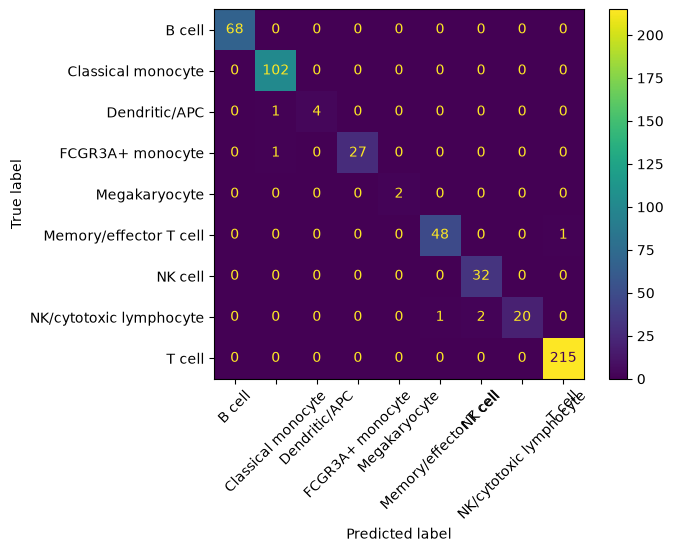

In [76]:
final_model = Pipeline([
    ("svd", TruncatedSVD(
        n_components=10,
        random_state=42
    )),
    ("logreg", LogisticRegression(
        max_iter=1000
    ))
])

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
final_model_accuracy = accuracy_score(
    y_test,
    y_pred
)
print("Final log reg model accuracy:", final_model_accuracy)

cm = confusion_matrix(
    y_test, y_pred, labels=final_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot(
    xticks_rotation=45
)

NK/cytotoxic lymphocyte is being confused with NK cell which is not suprising. FCGR3A+ monocyte is being confused with classical monocyte which is also not suprising. Dendritic/APC is being confused with classical monocyte, which is more concerning but only 1 cell was misclassified. There were only 5 observances of dendritic/APC cells, so the recall is 80%. The result doesn't need to be taken as seriously because there were only 5 cells to observe.

The classifier achieved high overall accuracy, with most errors occurring between biologically related populations, particularly NK/cytotoxic lymphocytes versus NK cells and FCGR3A+ versus classical monocytes. This suggests that the model successfully distinguishes major immune lineages while having greater difficulty resolving closely related subpopulations.

Which individual genes are most useful for distinguishing cell types? Using several genes is more biologically interpretable. Cells can be classified based on their expression in these genes. 


# Lost from here
I'm retraining the log reg model on al 1987 genes for the purpose of looking at the coefficients that push each gene towards or away from predicting a certain label.

In [77]:
# create a new log reg model 
gene_model = LogisticRegression(
    max_iter=2000,
    C=1.0 # strength of regularization, weak penalty
)

# train and test on gene expression data with 2000 genes as features
gene_model.fit(X_train, y_train)
y_pred_gene = gene_model.predict(X_test)

# evaluate
gene_accuracy = accuracy_score(
    y_test,
    y_pred_gene
)

print(f"Gene-level accuracy: {gene_accuracy:.3f}")

Gene-level accuracy: 0.964


Now we look at gene coefficients to see which genes are most helpful in determining cell type.

In [78]:
gene_model.coef_.shape
# 9 cell type classes, 1987 genes 
# you have a coeff for every gene and cell type class

(9, 1987)

In [79]:
gene_model.coef_

array([[-0.09298402, -0.00315158, -0.02321616, ..., -0.00025235,
         0.00728307, -0.04197624],
       [-0.00692174,  0.00229323, -0.00654426, ..., -0.00516123,
        -0.00154308, -0.04340872],
       [ 0.03293897,  0.00773798,  0.00868587, ...,  0.0138785 ,
        -0.01124834,  0.00482954],
       ...,
       [-0.01421298, -0.00220709,  0.00195958, ..., -0.00079601,
         0.07064685,  0.05299691],
       [-0.04011072,  0.0059465 , -0.0338031 , ..., -0.00376925,
        -0.07450893,  0.0418592 ],
       [ 0.148372  , -0.00549131,  0.09266818, ..., -0.01939382,
         0.00772658,  0.07615572]], shape=(9, 1987), dtype=float32)

I'm looking at just the B cell coeffs firstly.

In [80]:
# make a df of just the B cell coeffs to see what genes drive a cell to be classified as a B cell
bcell_coef = pd.DataFrame({
    "gene": adata.var_names,
    "coefficient": gene_model.coef_[0]
})

# largest coeff tells us it drives it towards B cell a lot
bcell_coef.sort_values(
    "coefficient",
    ascending=False
).head(20)

,gene,coefficient
1852,CD79A,0.409066
1646,CD79B,0.398771
1093,MS4A1,0.340564
654,HLA-DPB1,0.316723
646,HLA-DRB1,0.300172
653,HLA-DPA1,0.259456
648,HLA-DQB1,0.254120
1872,CD37,0.224419
647,HLA-DQA1,0.218097
1405,LINC00926,0.212902


In [81]:
# we look at genes that push away from classifying a cell as B cell
bcell_coef.sort_values(
    "coefficient",
    ascending=True
).head(20)

,gene,coefficient
1459,IL32,-0.204353
1714,CST3,-0.162420
1598,CCL5,-0.148374
1007,SRGN,-0.126199
639,AIF1,-0.112774
130,S100A6,-0.107985
1833,TYROBP,-0.100781
127,S100A11,-0.096522
793,GIMAP4,-0.095856
158,FCER1G,-0.095741


MS4A1, CD79A, CD79B, CD37 are positive coefficients for B cells, so they indicate a cell to be B cell more, relative to the other classes. 
NKG7, GNLY, S100A8, FCN1 are negatve coefficients, so they indicate that they are not B cells. 

A function to see what genes are indicative of each cell type. This function is reusable, to see the top genes for every class. 

In [82]:
gene_model.classes_

array(['B cell', 'Classical monocyte', 'Dendritic/APC',
       'FCGR3A+ monocyte', 'Megakaryocyte', 'Memory/effector T cell',
       'NK cell', 'NK/cytotoxic lymphocyte', 'T cell'], dtype=object)

In [83]:
# takes in the model, class name, and top n genes 
def top_genes_for_class(model, class_name, n=4):
    # grab index number of the class you want to look at 
    class_index = list(model.classes_).index(class_name)

    # getting coeffs of each gene for the cell type
    coefficients = pd.DataFrame({
        "gene": adata.var_names,
        "coefficient": model.coef_[class_index]
    })

    # return top n coeffs for a particular cell type 
    return coefficients.sort_values(
        "coefficient",
        ascending=False
    ).head(n)

for cell_type in gene_model.classes_:
    print("\n", cell_type)
    print(top_genes_for_class(gene_model, cell_type))


 B cell
          gene  coefficient
1852     CD79A     0.409066
1646     CD79B     0.398771
1093     MS4A1     0.340564
654   HLA-DPB1     0.316723

 Classical monocyte
        gene  coefficient
129   S100A8     0.523719
1937  LGALS2     0.455943
965     FCN1     0.417811
1119   GSTP1     0.301516

 Dendritic/APC
          gene  coefficient
1714      CST3     0.175551
647   HLA-DQA1     0.173247
148     FCER1A     0.160221
490        IGJ     0.144894

 FCGR3A+ monocyte
        gene  coefficient
160   FCGR3A     0.448484
637     LST1     0.312293
1051  IFITM3     0.265675
639     AIF1     0.265606

 Megakaryocyte
          gene  coefficient
494       PPBP     0.088062
493        PF4     0.075980
307       SDPR     0.075938
626  HIST1H2AC     0.075921

 Memory/effector T cell
      gene  coefficient
1598  CCL5     1.007612
545   GZMK     0.645147
1459  IL32     0.272602
537   IL7R     0.232627

 NK cell
        gene  coefficient
268     GNLY     0.510511
1833  TYROBP     0.300539
1317  

Earlier, I discovered top genes for each cluster using rank_gene_groups from scanpy, which was unsupervised. I want to know if the supervised logistic regression is consistent with that (it is). This shows the same genes as rank_gene_groups did.  

<function matplotlib.pyplot.show(close=None, block=None)>

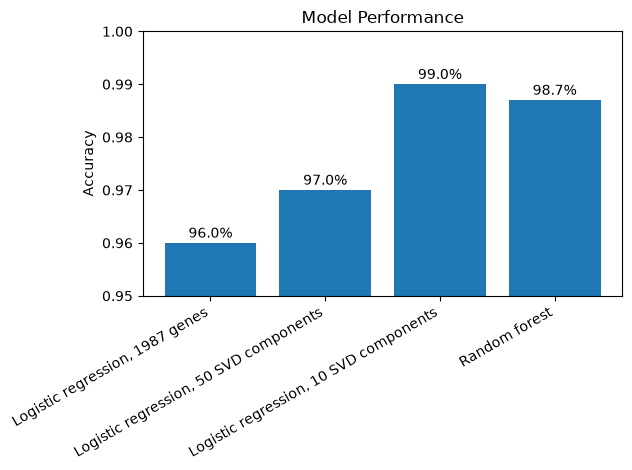

In [84]:
models = list(model_results.keys())
accuracies = list(model_results.values())
plt.bar(models, accuracies)
plt.ylabel("Accuracy")
plt.title("Model Performance")
plt.ylim(0, 1)

for i, value in enumerate(model_results.values()):
    plt.text(i, value + 0.001, f"{value:.1%}", ha="center")
    
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.ylim(0.95, 1.0)
plt.show

Summary:
1. The dataset started with 2700 cells and 32,738 genes. 
2. After QC, I used unsupervised clustering to identify 9 cell populations (B cells, T cells, NK cells, classical monocytes, FCGR3A+ monocytes, dendritic/APC, megakaryocytes). I examined each cluster's top marker genes to see which cell populations they best represented. 
3. The first model used all 1987 highly variable genes to classify, and its accuracy was the lowest, at 96%. The second was logistic regression with 50 SVD components as features, increasing the accuracy to 97%. The best model was the logistic regression with 10 SVD components, producing an accuracy of 99%. The last model, a more complex random forest model didn't improve the linear model. Accuracy was 98.7%, which was very close to the linear model, but slightly lower in accuracy. RF did show that components 2-4 were particularly informative. Component 2 mapped to monocyte/myeloid genes such as S100A8, TYROBP, LST1, FCN1. Component 3 mapped to cytotoxic/B-cell/antigen-presentation programs including NKG7, GNLY, CD79A, MS4A1, HLA genes. Component 3 mapped to antigen-presentation and cytotoxic/lymphocyte programs. The confusion matrix showed errors mostly between biologically similar populations. 
5. I did hyperparameter testing of which principle components would be best to use via 5-fold cross validation. The pcs >= 10 did not provide any more meaningful variation. Therefore, the best model was the log reg with 10 pcs. 
6. Lastly, I wanted to see which genes were markers for the different cell types, and if my supervised logistic regression coefficients would corroborate with what scanpy's unsupervised rank_gene_groups() produced. The genes were shared, which shows that two different methods can show the same result.